# ✈️ Real-World Dataset Analysis: Why Are Flights Delayed at New York's Airports?

**Author:** Juhi Parnami &nbsp;|&nbsp; **Dataset:** `nycflights13` (real 2013 flights from JFK, LGA and EWR) &nbsp;|&nbsp; **Tools:** pandas, NumPy, SciPy, statsmodels, scikit-learn, Matplotlib, Seaborn

## Notebook roadmap (maps to the 6 objectives of the task)

| # | Objective | Section |
|---|---|---|
| 1 | Select a real-world dataset and understand its context | 1 |
| 2 | Explore structure, data types, distributions, missing values, duplicates, relationships | 2 |
| 3 | Clean and preprocess | 3 |
| 4 | Exploratory data analysis with statistics | 4 and 5 |
| 5 | Visualizations | throughout (15 figures) |
| 6 | Insights, interpretations, conclusions, recommendations | 6, 7 and 8 |

## 1. Dataset selection and business context

### Why this dataset?
Delays cost airlines money and cost passengers time, so understanding **what drives delays** is a genuine operations question. I chose `nycflights13` because it is **real**, **large** (336,776 rows), **messy in realistic ways**, and **linkable** to other real tables (weather, aircraft, airlines, airports).

| Item | Detail |
|---|---|
| **Flights** | Every scheduled departure from New York City's three airports (**JFK, LGA, EWR**) in **2013**. Operational data from the **U.S. Bureau of Transportation Statistics (BTS)** |
| **Weather** | Hourly observations per airport, originally from **NOAA** (US weather agency) |
| **Planes / Airlines / Airports** | Aircraft registry details, carrier names and airport names (FAA and BTS reference data) |
| **Access** | The `nycflights13` Python package (an open dataset, widely used in data science teaching) |

### The business problem
> *An airport operations manager wants to know **when, where and why** flights are delayed or cancelled, so that scheduling and staffing decisions can reduce delays.*

### Analytical questions
1. How large is the delay problem overall, and how skewed are the delays?
2. Do carriers and airports differ **significantly**, and by how much?
3. How do delays change with **time of day** and **season**?
4. How strongly do departure delays carry over to arrival delays, and can flights recover time in the air?
5. Does **weather** matter, and how much?
6. What explains **cancellations**?
7. Can delay risk be **predicted** from information known *before* departure?

### Definitions used (industry standard)
- A flight is **delayed** when it arrives (or departs) **15 or more minutes** after schedule (the U.S. Department of Transportation definition).
- Negative delay = the flight was **early**.

In [1]:
import json
import platform
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import nycflights13 as nf
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels
import statsmodels.api as sm
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from statsmodels.stats.proportion import proportion_confint

from src.cleaning import classify_status, clean_weather, hhmm_to_minutes, iqr_bounds

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
sns.set_theme(style="whitegrid", context="notebook")
PRIMARY, ACCENT, DARK, GREEN = "#4F46E5", "#F97316", "#1E293B", "#16A34A"

FIG, TAB = Path("outputs/figures"), Path("outputs/tables")
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
R = {}   # every key number is stored here and saved to outputs/results.json

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150, bbox_inches="tight"); plt.show()

print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__}")
print(f"statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | Matplotlib {matplotlib.__version__} | Seaborn {sns.__version__}")

Python 3.12.3 | pandas 3.0.2 | NumPy 2.4.4 | SciPy 1.17.1
statsmodels 0.15.0 | scikit-learn 1.8.0 | Matplotlib 3.10.8 | Seaborn 0.13.2


## 2. Data exploration
### 2.1 Load the tables and check their size

In [2]:
flights = nf.flights.copy()
weather = nf.weather.copy()
planes = nf.planes.copy()
airlines = nf.airlines.copy()
airports = nf.airports.copy()

sizes = pd.DataFrame({"table": ["flights", "weather", "planes", "airlines", "airports"],
                      "rows": [len(flights), len(weather), len(planes), len(airlines), len(airports)],
                      "columns": [flights.shape[1], weather.shape[1], planes.shape[1], airlines.shape[1], airports.shape[1]]})
R["n_flights"], R["n_weather"], R["n_planes"] = len(flights), len(weather), len(planes)
sizes

,table,rows,columns
0,flights,336776,19
1,weather,26115,15
2,planes,3322,9
3,airlines,16,2
4,airports,1458,8


### Data dictionary (main columns)

| Column | Meaning | Statistical type |
|---|---|---|
| `year, month, day` | Date of the scheduled departure | Discrete / ordinal |
| `dep_time, arr_time` | Actual times as **hhmm integers** (e.g. 517 = 5:17) | Needs conversion |
| `sched_dep_time, sched_arr_time` | Scheduled times (hhmm) | Needs conversion |
| `dep_delay, arr_delay` | Delay in **minutes** (negative = early) | Continuous |
| `carrier, origin, dest` | Airline code, departure airport, destination | Nominal |
| `air_time, distance` | Minutes in the air; route length in miles | Continuous |
| `hour` | Scheduled departure hour (0-23) | Discrete |
| `time_hour` | Scheduled departure rounded to the hour (UTC text) | Datetime stored as text |
| Weather: `temp, humid, wind_speed, visib, precip` | Temperature (F), humidity (%), wind (mph), visibility (miles), rain (inches) | Continuous |

### 2.2 Structure and data types

In [3]:
flights.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            336776 non-null  int64  
 1   month           336776 non-null  int64  
 2   day             336776 non-null  int64  
 3   dep_time        328521 non-null  float64
 4   sched_dep_time  336776 non-null  int64  
 5   dep_delay       328521 non-null  float64
 6   arr_time        328063 non-null  float64
 7   sched_arr_time  336776 non-null  int64  
 8   arr_delay       327346 non-null  float64
 9   carrier         336776 non-null  str    
 10  flight          336776 non-null  int64  
 11  tailnum         334264 non-null  str    
 12  origin          336776 non-null  str    
 13  dest            336776 non-null  str    
 14  air_time        327346 non-null  float64
 15  distance        336776 non-null  int64  
 16  hour            336776 non-null  int64  
 17  minute          33677

In [4]:
flights.describe().T

,count,mean,std,min,25%,50%,75%,max
year,"336,776.00","2,013.00",0.00,"2,013.00","2,013.00","2,013.00","2,013.00","2,013.00"
month,"336,776.00",6.55,3.41,1.00,4.00,7.00,10.00,12.00
day,"336,776.00",15.71,8.77,1.00,8.00,16.00,23.00,31.00
dep_time,"328,521.00","1,349.11",488.28,1.00,907.00,"1,401.00","1,744.00","2,400.00"
sched_dep_time,"336,776.00","1,344.25",467.34,106.00,906.00,"1,359.00","1,729.00","2,359.00"
dep_delay,"328,521.00",12.64,40.21,-43.00,-5.00,-2.00,11.00,"1,301.00"
arr_time,"328,063.00","1,502.05",533.26,1.00,"1,104.00","1,535.00","1,940.00","2,400.00"
sched_arr_time,"336,776.00","1,536.38",497.46,1.00,"1,124.00","1,556.00","1,945.00","2,359.00"
arr_delay,"327,346.00",6.90,44.63,-86.00,-17.00,-5.00,14.00,"1,272.00"
flight,"336,776.00","1,971.92","1,632.47",1.00,553.00,"1,496.00","3,465.00","8,500.00"


### 2.3 Missing values
**Idea:** missing data is only harmful if we do not understand *why* it is missing. We first count it, then explain it.

In [5]:
miss = flights.isna().sum()
miss = miss[miss > 0].to_frame("missing")
miss["percent"] = miss["missing"] / len(flights) * 100
print(miss)

flights["status"] = classify_status(flights)
status_counts = flights["status"].value_counts()
print("\nWhat actually happened to each flight:")
print(pd.DataFrame({"flights": status_counts, "percent": status_counts / len(flights) * 100}))
R["status_counts"] = {k: int(v) for k, v in status_counts.items()}
R["missing_flights"] = {k: int(v) for k, v in miss["missing"].items()}

           missing  percent
dep_time      8255     2.45
dep_delay     8255     2.45
arr_time      8713     2.59
arr_delay     9430     2.80
tailnum       2512     0.75
air_time      9430     2.80

What actually happened to each flight:
                    flights  percent
status                              
Completed            327346    97.20
Cancelled              8255     2.45
Delay not recorded      717     0.21
Diverted                458     0.14


**Reading the result:** the missing `dep_time`/`dep_delay` values are **not random errors**. They are flights that were **cancelled** (they never departed), and the extra missing arrival values are **diverted** flights. Missing here carries real business meaning, so **imputing (filling) these delays would be wrong**: a cancelled flight does not have a "typical delay".

### 2.4 Duplicates, special values and data-type problems

In [6]:
key = ["year", "month", "day", "carrier", "flight", "origin", "sched_dep_time"]
R["dup_full"] = int(flights.drop(columns="status").duplicated().sum())
R["dup_key"] = int(flights.duplicated(key).sum())
R["dep_2400"] = int((flights["dep_time"] == 2400).sum())
R["arr_2400"] = int((flights["arr_time"] == 2400).sum())
R["weather_dup_key"] = int(weather.duplicated(["origin", "time_hour"]).sum())
R["planes_dup_tail"] = int(planes.duplicated("tailnum").sum())

print(f"Fully duplicated flight rows           : {R['dup_full']}")
print(f"Duplicates on the business key         : {R['dup_key']}  (same carrier, flight, airport, date, scheduled time)")
print(f"Weather rows duplicated on origin+hour : {R['weather_dup_key']}")
print(f"Duplicate aircraft in planes table     : {R['planes_dup_tail']}")
print(f"Times stored as 2400 (should be 0)     : dep {R['dep_2400']}, arr {R['arr_2400']}")
print(f"\nData-type problems: times are hhmm integers (not real times); time_hour is text -> {flights['time_hour'].dtype}")

Fully duplicated flight rows           : 0
Duplicates on the business key         : 0  (same carrier, flight, airport, date, scheduled time)
Weather rows duplicated on origin+hour : 0
Duplicate aircraft in planes table     : 0
Times stored as 2400 (should be 0)     : dep 29, arr 150

Data-type problems: times are hhmm integers (not real times); time_hour is text -> str


### 2.5 Weather table quality

In [7]:
wcols = ["temp", "dewp", "humid", "wind_speed", "wind_gust", "precip", "visib", "pressure"]
print(weather[wcols].describe().T[["count", "min", "50%", "max"]])
R["wind_over_100"] = int((weather["wind_speed"] > 100).sum())
R["wind_max_raw"] = float(weather["wind_speed"].max())
R["weather_missing"] = {c: int(weather[c].isna().sum()) for c in wcols if weather[c].isna().sum() > 0}
R["gust_missing_pct"] = float(weather["wind_gust"].isna().mean() * 100)
R["pressure_missing_pct"] = float(weather["pressure"].isna().mean() * 100)
print(f"\nMaximum wind speed in the raw data: {R['wind_max_raw']:.1f} mph (impossible: the strongest wind ever recorded on Earth is about 253 mph)")
print(f"wind_gust missing: {R['gust_missing_pct']:.1f}% | pressure missing: {R['pressure_missing_pct']:.1f}%")

               count    min      50%      max
temp       26,114.00  10.94    55.40   100.04
dewp       26,114.00  -9.94    42.08    78.08
humid      26,114.00  12.74    61.79   100.00
wind_speed 26,111.00   0.00    10.36 1,048.36
wind_gust   5,337.00  16.11    24.17    66.75
precip     26,115.00   0.00     0.00     1.21
visib      26,115.00   0.00    10.00    10.00
pressure   23,386.00 983.80 1,017.60 1,042.10

Maximum wind speed in the raw data: 1048.4 mph (impossible: the strongest wind ever recorded on Earth is about 253 mph)
wind_gust missing: 79.6% | pressure missing: 10.4%


### 2.6 Distributions of the key variables

In [8]:
d = flights["dep_delay"].dropna(); a = flights["arr_delay"].dropna()
def dist_row(s):
    return {"count": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(), "skewness": s.skew(),
            "min": s.min(), "p90": s.quantile(.9), "p99": s.quantile(.99), "max": s.max()}
dist = pd.DataFrame({"dep_delay": dist_row(d), "arr_delay": dist_row(a), "distance": dist_row(flights["distance"])}).T
R["dist"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in dist.T.to_dict().items()}
dist

,count,mean,median,std,skewness,min,p90,p99,max
dep_delay,"328,521.00",12.64,-2.00,40.21,4.80,-43.00,49.00,191.00,"1,301.00"
arr_delay,"327,346.00",6.90,-5.00,44.63,3.72,-86.00,52.00,190.00,"1,272.00"
distance,"336,776.00","1,039.91",872.00,733.23,1.13,17.00,"2,446.00","2,586.00","4,983.00"


In [9]:
# Outliers by the IQR rule (Tukey fences): flagged, but are they errors?
for col in ["dep_delay", "arr_delay"]:
    s = flights[col].dropna(); lo, hi = iqr_bounds(s)
    n_out = int(((s < lo) | (s > hi)).sum())
    R[f"iqr_out_{col}"] = n_out; R[f"iqr_hi_{col}"] = float(hi)
    print(f"{col}: fences ({lo:.0f}, {hi:.0f}) min -> {n_out:,} outliers ({n_out / len(s):.1%}); largest = {s.max():,.0f} min ({s.max() / 60:.1f} hours)")
worst = flights.loc[flights["dep_delay"].idxmax(), ["month", "day", "carrier", "flight", "origin", "dest", "dep_delay", "arr_delay"]]
print("\nLongest departure delay is a genuine record, not a typo:\n", worst.to_string())

dep_delay: fences (-29, 35) min -> 43,216 outliers (13.2%); largest = 1,301 min (21.7 hours)
arr_delay: fences (-64, 60) min -> 27,880 outliers (8.5%); largest = 1,272 min (21.2 hours)

Longest departure delay is a genuine record, not a typo:
 month              1
day                9
carrier           HA
flight            51
origin           JFK
dest             HNL
dep_delay   1,301.00
arr_delay   1,272.00


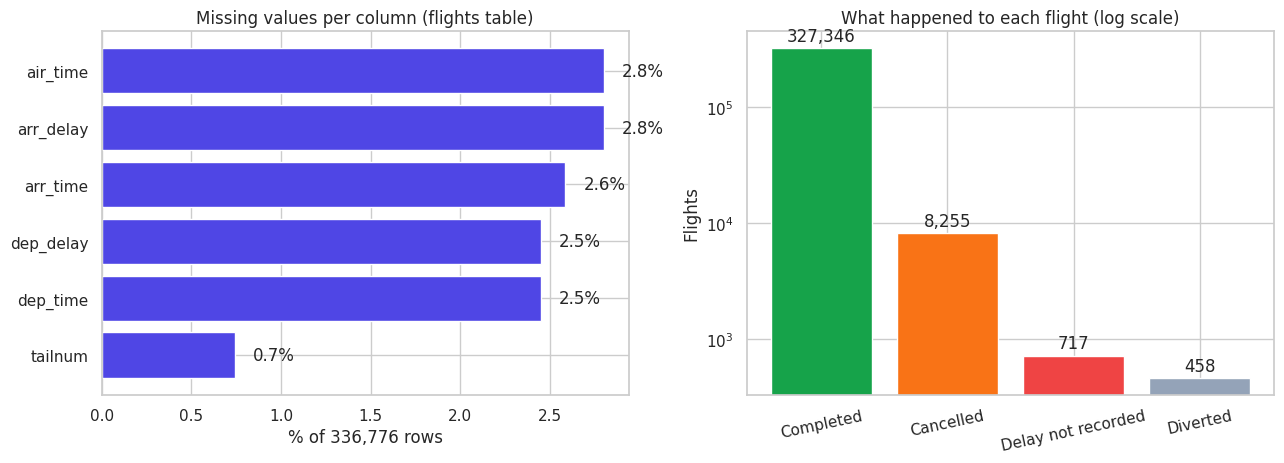

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
share = miss["percent"].sort_values()
axes[0].barh(share.index, share.values, color=PRIMARY)
for i, v in enumerate(share.values): axes[0].text(v + 0.1, i, f"{v:.1f}%", va="center")
axes[0].set(title="Missing values per column (flights table)", xlabel="% of 336,776 rows")
st = flights["status"].value_counts()
axes[1].bar(st.index, st.values, color=[GREEN, ACCENT, "#EF4444", "#94A3B8"][: len(st)])
axes[1].set_yscale("log"); axes[1].set(title="What happened to each flight (log scale)", ylabel="Flights")
for i, v in enumerate(st.values): axes[1].text(i, v * 1.15, f"{v:,}", ha="center")
plt.setp(axes[1].get_xticklabels(), rotation=12)
save(fig, "01_missing_and_status.png")

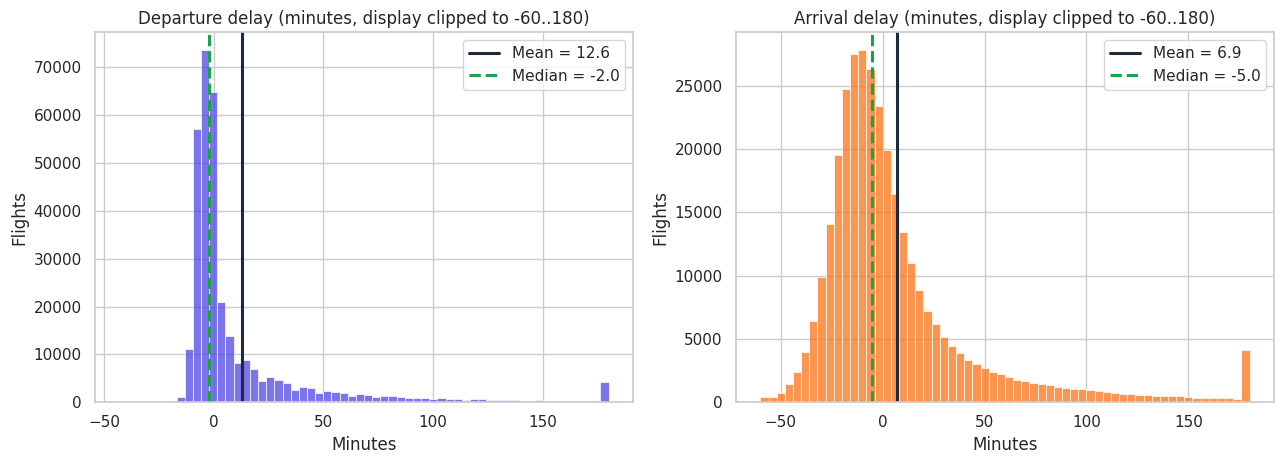

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, color, label in [(axes[0], "dep_delay", PRIMARY, "Departure delay"), (axes[1], "arr_delay", ACCENT, "Arrival delay")]:
    s = flights[col].dropna()
    sns.histplot(s.clip(-60, 180), bins=60, color=color, ax=ax)
    ax.axvline(s.mean(), color=DARK, lw=2.2, label=f"Mean = {s.mean():.1f}")
    ax.axvline(s.median(), color=GREEN, lw=2.2, ls="--", label=f"Median = {s.median():.1f}")
    ax.set(title=f"{label} (minutes, display clipped to -60..180)", xlabel="Minutes", ylabel="Flights"); ax.legend()
save(fig, "02_delay_distribution.png")

**Reading the figures:** both delay distributions are **strongly right-skewed**: most flights leave on time or early, but a long tail of very late flights drags the **mean far above the median**. This is why the analysis below prefers the **median**, **percent delayed** and **rank-based tests** to plain averages and t-tests.

## 3. Cleaning and preprocessing
Every step is logged with its **count**, its **technique** and its **reason**, so that the cleaning is auditable.

In [12]:
clean_log = []
def log_step(issue, count, action, reason):
    clean_log.append({"issue": issue, "count": count, "action": action, "reason": reason})

n_raw = len(flights)

# ---- 3.1 Missing values that mean something: keep them, label them -----------------------
log_step("Missing departure data (cancelled flights)", R["status_counts"]["Cancelled"],
         "Labelled status = Cancelled; excluded from delay statistics but analysed separately",
         "A cancelled flight has no delay; imputing one would invent data")
log_step("Missing arrival data (diverted flights)", R["status_counts"]["Diverted"],
         "Labelled status = Diverted; excluded from arrival-delay statistics", "They never reached the planned destination")
log_step("Arrival delay not recorded", R["status_counts"]["Delay not recorded"],
         "Labelled; excluded from arrival-delay statistics", "Cannot be reconstructed reliably")

# ---- 3.2 Incorrect data types: hhmm integers -> minutes, text -> datetime ---------------
for col in ["dep_time", "arr_time", "sched_dep_time", "sched_arr_time"]:
    flights[col + "_min"] = hhmm_to_minutes(flights[col])
log_step("Times stored as hhmm integers (e.g. 517)", n_raw, "Converted to minutes after midnight (517 -> 317); 2400 -> 0",
         "Integers like 1230 vs 1229 look 1 apart but are 61 minutes apart")
log_step("Time value 2400 (midnight)", R["dep_2400"] + R["arr_2400"], "Mapped to 0", "2400 is not a valid clock time")

flights["time_hour"] = pd.to_datetime(flights["time_hour"], utc=True)
flights["date"] = pd.to_datetime(dict(year=flights["year"], month=flights["month"], day=flights["day"]))
flights["weekday"] = flights["date"].dt.day_name()
log_step("time_hour stored as text", n_raw, "Converted to timezone-aware datetime; built date and weekday", "Needed for joining weather and for time analysis")

# ---- 3.3 Duplicates -------------------------------------------------------------------
log_step("Duplicate flight records", R["dup_full"] + R["dup_key"], "None found (checked full rows and the business key)", "Verified, nothing removed")

# ---- 3.4 Weather: impossible value + gaps ---------------------------------------------
weather_clean, wlog = clean_weather(weather)
log_step("Impossible wind speed (1,048 mph)", wlog["impossible_wind"], "Set to missing, then interpolated within the same airport (max 6 hours)",
         "Physically impossible; most likely a sensor or entry error")
log_step("Short weather gaps (temp, humidity, wind, direction, pressure)", sum(wlog["missing_before"].values()) - 0,
         "Linear interpolation within airport, limit 6 hours",
         "Weather changes smoothly hour to hour, so short gaps can be filled safely")
log_step("wind_gust missing in " + f"{R['gust_missing_pct']:.0f}% of hours", int(weather["wind_gust"].isna().sum()),
         "Not imputed and NOT used in models", "Gusts are only reported when significant, so missing = no gusts, not unknown")
R["weather_log"] = wlog
print("Weather cleaning log:", wlog)

Weather cleaning log: {'impossible_wind': 1, 'missing_before': {'temp': 1, 'dewp': 1, 'humid': 1, 'wind_speed': 5, 'wind_dir': 460, 'pressure': 2729}, 'missing_after': {'temp': 0, 'dewp': 0, 'humid': 0, 'wind_speed': 0, 'wind_dir': 0, 'pressure': 0}}


In [13]:
# ---- 3.5 Merge: flights + weather + planes + airline names (validated left joins) ------
fl = flights.merge(weather_clean[["origin", "time_hour", "temp", "humid", "wind_speed", "visib", "precip"]],
                   on=["origin", "time_hour"], how="left", validate="m:1")
fl = fl.merge(planes[["tailnum", "year"]].rename(columns={"year": "plane_year"}), on="tailnum", how="left", validate="m:1")
fl = fl.merge(airlines.rename(columns={"name": "airline"}), on="carrier", how="left", validate="m:1")
assert len(fl) == n_raw, "a merge changed the number of flights"
R["no_weather_rows"] = int(fl["temp"].isna().sum())
R["no_plane_rows"] = int(fl["plane_year"].isna().sum())
print(f"Rows after merges: {len(fl):,} (unchanged: {len(fl) == n_raw})")
print(f"Flights with no matching weather hour: {R['no_weather_rows']:,} ({R['no_weather_rows'] / n_raw:.1%})")
print(f"Flights with unknown aircraft age    : {R['no_plane_rows']:,} ({R['no_plane_rows'] / n_raw:.1%})")
log_step("Flights without a weather record for their hour", R["no_weather_rows"], "Kept; weather columns stay missing (rows dropped only inside the model)", "Missing hours in the weather table")
log_step("Flights with unknown aircraft age", R["no_plane_rows"], "Kept; age missing, flagged in the model", "Tail number absent from the planes registry")

# ---- 3.6 Derived features --------------------------------------------------------------
fl["dep_delayed"] = np.where(fl["dep_delay"].notna(), fl["dep_delay"] >= 15, np.nan)
fl["arr_delayed"] = np.where(fl["status"].eq("Completed"), fl["arr_delay"] >= 15, np.nan)
fl["is_cancelled"] = fl["status"].eq("Cancelled")
fl["air_gain"] = fl["dep_delay"] - fl["arr_delay"]           # minutes made up in the air
fl["aircraft_age"] = 2013 - fl["plane_year"]
fl["dist_band"] = pd.cut(fl["distance"], [0, 500, 1000, 2000, 5000], labels=["<500 mi", "500-1,000", "1,000-2,000", ">2,000 mi"])
fl["tod"] = pd.cut(fl["hour"], [-1, 8, 11, 16, 20, 24], labels=["Early (to 8)", "Late morning (9-11)", "Afternoon (12-16)", "Evening (17-20)", "Night (21+)"])
fl["season"] = fl["month"].map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"})
for c in ["carrier", "origin", "dest", "status"]:
    fl[c] = fl[c].astype("category")
log_step("Needed analysis columns", n_raw, "Created delayed flags (>=15 min), air_gain, aircraft_age, distance band, time-of-day band, season, categorical types", "Domain-standard definitions and compact types")

# ---- 3.7 Analysis subsets (so every statistic states its denominator) -----------------
dep_ok = fl[fl["dep_delay"].notna()].copy()                  # flights that departed
arr_ok = fl[fl["status"] == "Completed"].copy()               # flights with a recorded arrival delay
R["n_dep_ok"], R["n_arr_ok"] = len(dep_ok), len(arr_ok)
print(f"Flights that departed: {len(dep_ok):,} | flights with an arrival delay: {len(arr_ok):,}")

cleaning_table = pd.DataFrame(clean_log)
cleaning_table.to_csv(TAB / "cleaning_log.csv", index=False)
R["cleaning_table"] = clean_log
cleaning_table[["issue", "count", "action"]]

Rows after merges: 336,776 (unchanged: True)
Flights with no matching weather hour: 1,556 (0.5%)
Flights with unknown aircraft age    : 57,912 (17.2%)


Flights that departed: 328,521 | flights with an arrival delay: 327,346


,issue,count,action
0,Missing departure data (cancelled flights),8255,Labelled status = Cancelled; excluded from del...
1,Missing arrival data (diverted flights),458,Labelled status = Diverted; excluded from arri...
2,Arrival delay not recorded,717,Labelled; excluded from arrival-delay statistics
3,Times stored as hhmm integers (e.g. 517),336776,Converted to minutes after midnight (517 -> 31...
4,Time value 2400 (midnight),179,Mapped to 0
5,time_hour stored as text,336776,Converted to timezone-aware datetime; built da...
6,Duplicate flight records,0,None found (checked full rows and the business...
7,"Impossible wind speed (1,048 mph)",1,"Set to missing, then interpolated within the s..."
8,"Short weather gaps (temp, humidity, wind, dire...",3197,"Linear interpolation within airport, limit 6 h..."
9,wind_gust missing in 80% of hours,20778,Not imputed and NOT used in models


**Outlier decision:** the IQR rule flags roughly 8% to 13% of delays (13.2% of departure delays and 8.5% of arrival delays), but the biggest ones (for example a 1,301-minute delay) are **real events**, not errors. Deleting them would hide the very thing we want to study, so they are **kept**, and robust methods (median, percent delayed, rank-based tests, Spearman) are used instead. Only the physically impossible wind speed was treated as an error.

## 4. Exploratory data analysis
### 4.1 How big is the delay problem?

In [14]:
n_dep, n_arr = len(dep_ok), len(arr_ok)
overall = {
    "cancel_rate": fl["is_cancelled"].mean() * 100,
    "dep_delayed_pct": dep_ok["dep_delayed"].mean() * 100, "arr_delayed_pct": arr_ok["arr_delayed"].mean() * 100,
    "dep_early_pct": (dep_ok["dep_delay"] < 0).mean() * 100, "dep_ontime_or_early_pct": (dep_ok["dep_delay"] < 15).mean() * 100,
    "arr_over60_pct": (arr_ok["arr_delay"] >= 60).mean() * 100, "arr_over120_pct": (arr_ok["arr_delay"] >= 120).mean() * 100,
    "dep_mean": dep_ok["dep_delay"].mean(), "dep_median": dep_ok["dep_delay"].median(),
    "arr_mean": arr_ok["arr_delay"].mean(), "arr_median": arr_ok["arr_delay"].median(),
}
# Concentration: how much of the total delay minutes comes from the worst 10% of delayed flights?
late = arr_ok.loc[arr_ok["arr_delay"] > 0, "arr_delay"].sort_values(ascending=False)
overall["top10pct_share_of_delay_minutes"] = late.head(int(len(late) * 0.10)).sum() / late.sum() * 100
overall["total_delay_hours"] = late.sum() / 60
R["overall"] = {k: float(v) for k, v in overall.items()}
for k, v in overall.items(): print(f"{k:34s}: {v:,.2f}")

cancel_rate                       : 2.45
dep_delayed_pct                   : 22.19
arr_delayed_pct                   : 24.47
dep_early_pct                     : 55.88
dep_ontime_or_early_pct           : 77.81
arr_over60_pct                    : 8.65
arr_over120_pct                   : 3.12
dep_mean                          : 12.64
dep_median                        : -2.00
arr_mean                          : 6.90
arr_median                        : -5.00
top10pct_share_of_delay_minutes   : 41.41
total_delay_hours                 : 89,428.57


### 4.2 Do airlines differ? (Kruskal-Wallis test, because delays are skewed)

In [15]:
def prop_ci(successes, n):
    lo, hi = proportion_confint(successes, n, alpha=0.05, method="wilson"); return lo * 100, hi * 100

g = arr_ok.groupby("carrier", observed=True)
carrier = g.agg(flights=("arr_delay", "size"), mean_arr=("arr_delay", "mean"), median_arr=("arr_delay", "median"),
                delayed=("arr_delayed", "sum")).reset_index()
carrier["pct_delayed"] = carrier["delayed"] / carrier["flights"] * 100
ci = [prop_ci(r.delayed, r.flights) for r in carrier.itertuples()]
carrier["ci_low"], carrier["ci_high"] = [c[0] for c in ci], [c[1] for c in ci]
carrier["cancel_rate"] = carrier["carrier"].map(fl.groupby("carrier", observed=True)["is_cancelled"].mean() * 100)
carrier = carrier.merge(airlines.rename(columns={"name": "airline"}), on="carrier").sort_values("pct_delayed", ascending=False)
carrier.to_csv(TAB / "carrier_summary.csv", index=False)

groups = [x["arr_delay"].to_numpy() for _, x in g]
H, p_kw = stats.kruskal(*groups)
k, n_tot = len(groups), len(arr_ok)
eps2 = (H - k + 1) / (n_tot - k)                      # epsilon-squared effect size
R["kw_carrier"] = {"H": float(H), "p": float(p_kw), "k": k, "epsilon2": float(eps2)}
R["carrier_table"] = carrier.round(2).to_dict("records")
print(f"Kruskal-Wallis across {k} carriers: H = {H:,.0f}, p = {p_kw:.1e}, epsilon-squared = {eps2:.3f}")
carrier[["airline", "flights", "mean_arr", "median_arr", "pct_delayed", "ci_low", "ci_high", "cancel_rate"]].round(1)

Kruskal-Wallis across 16 carriers: H = 8,565, p = 0.0e+00, epsilon-squared = 0.026


,airline,flights,mean_arr,median_arr,pct_delayed,ci_low,ci_high,cancel_rate
6,Frontier Airlines Inc.,681,21.90,6.00,38.80,35.20,42.50,0.44
7,AirTran Airways Corporation,3175,20.10,5.00,34.60,33.00,36.30,2.24
15,Mesa Airlines Inc.,544,15.60,-2.00,32.90,29.10,37.00,9.32
5,ExpressJet Airlines Inc.,51108,15.80,-1.00,32.10,31.70,32.50,5.20
9,Envoy Air,25037,10.80,-1.00,27.90,27.40,28.50,4.67
3,JetBlue Airways,54049,9.50,-3.00,27.00,26.60,27.30,0.85
14,Southwest Airlines Co.,12044,9.60,-3.00,25.70,24.90,26.50,1.56
0,Endeavor Air Inc.,17294,7.40,-7.00,25.60,24.90,26.20,5.66
10,SkyWest Airlines Inc.,29,11.90,-7.00,24.10,12.20,42.10,9.38
11,United Air Lines Inc.,57782,3.60,-6.00,22.50,22.20,22.80,1.17


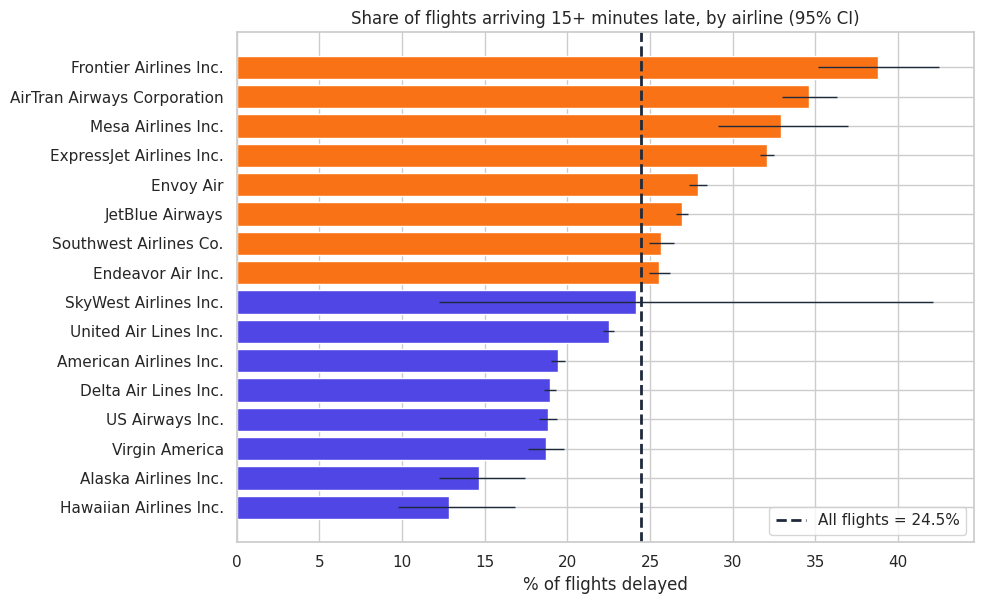

In [16]:
fig, ax = plt.subplots(figsize=(10, 6.2))
c = carrier.sort_values("pct_delayed")
colors = [ACCENT if v > R["overall"]["arr_delayed_pct"] else PRIMARY for v in c["pct_delayed"]]
ax.barh(c["airline"], c["pct_delayed"], xerr=[c["pct_delayed"] - c["ci_low"], c["ci_high"] - c["pct_delayed"]], color=colors, error_kw=dict(ecolor=DARK, lw=1))
ax.axvline(R["overall"]["arr_delayed_pct"], color=DARK, ls="--", lw=2, label=f"All flights = {R['overall']['arr_delayed_pct']:.1f}%")
ax.set(title="Share of flights arriving 15+ minutes late, by airline (95% CI)", xlabel="% of flights delayed"); ax.legend(loc="lower right")
save(fig, "03_carrier_delay_rate.png")

### 4.3 Do the three airports differ?

In [17]:
origin = (dep_ok.groupby("origin", observed=True).agg(dep_flights=("dep_delay", "size"), dep_mean=("dep_delay", "mean"),
          dep_median=("dep_delay", "median"), dep_delayed_pct=("dep_delayed", lambda s: s.mean() * 100)).reset_index())
origin["arr_delayed_pct"] = origin["origin"].map(arr_ok.groupby("origin", observed=True)["arr_delayed"].mean() * 100)
origin["cancel_rate"] = origin["origin"].map(fl.groupby("origin", observed=True)["is_cancelled"].mean() * 100)
names = {"EWR": "Newark (EWR)", "JFK": "John F. Kennedy (JFK)", "LGA": "LaGuardia (LGA)"}
origin["airport"] = origin["origin"].map(names)
H2, p_o = stats.kruskal(*[x["dep_delay"].to_numpy() for _, x in dep_ok.groupby("origin", observed=True)])
R["kw_origin"] = {"H": float(H2), "p": float(p_o)}
R["origin_table"] = origin.round(2).to_dict("records")
origin.to_csv(TAB / "origin_summary.csv", index=False)
print(f"Kruskal-Wallis across airports (departure delay): H = {H2:,.0f}, p = {p_o:.1e}")
origin.round(1)

Kruskal-Wallis across airports (departure delay): H = 5,368, p = 0.0e+00


,origin,dep_flights,dep_mean,dep_median,dep_delayed_pct,arr_delayed_pct,cancel_rate,airport
0,EWR,117596,15.10,-1.00,25.30,26.34,2.68,Newark (EWR)
1,JFK,109416,12.10,-1.00,21.30,23.70,1.67,John F. Kennedy (JFK)
2,LGA,101509,10.30,-3.00,19.50,23.14,3.01,LaGuardia (LGA)


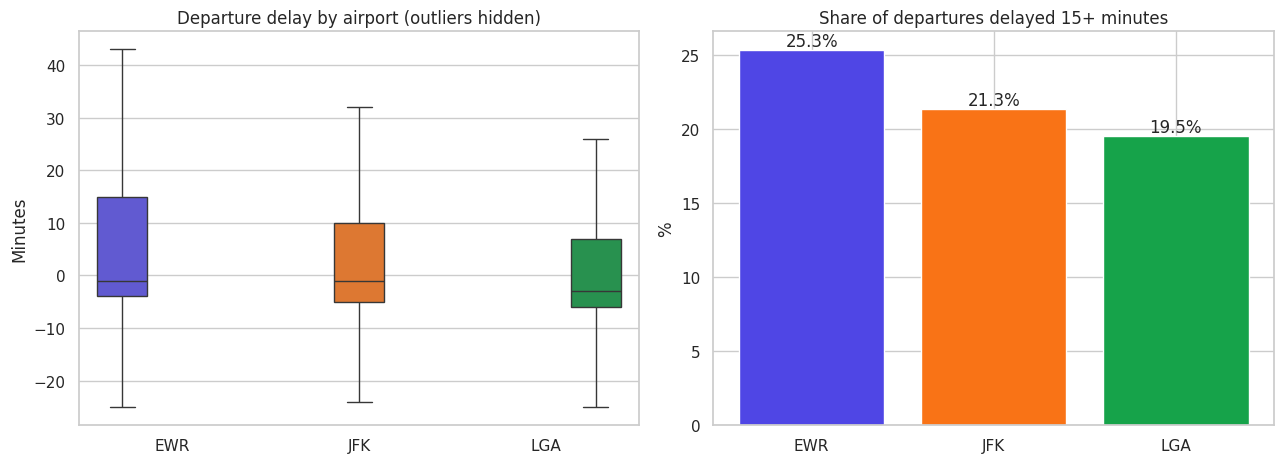

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=dep_ok, x="origin", y="dep_delay", hue="origin", palette=[PRIMARY, ACCENT, GREEN], showfliers=False, legend=False, ax=axes[0])
axes[0].set(title="Departure delay by airport (outliers hidden)", xlabel="", ylabel="Minutes")
axes[1].bar(origin["origin"], origin["dep_delayed_pct"], color=[PRIMARY, ACCENT, GREEN][:3])
for i, v in enumerate(origin["dep_delayed_pct"]): axes[1].text(i, v + 0.3, f"{v:.1f}%", ha="center")
axes[1].set(title="Share of departures delayed 15+ minutes", ylabel="%")
save(fig, "04_airport_comparison.png")

### 4.4 Time of day: do delays build up during the day?

In [19]:
hour = (dep_ok[dep_ok["hour"].between(5, 23)].groupby("hour")
        .agg(flights=("dep_delay", "size"), mean_dep=("dep_delay", "mean"), sem=("dep_delay", "sem"),
             delayed_pct=("dep_delayed", lambda s: s.mean() * 100)).reset_index())
hour["ci"] = 1.96 * hour["sem"]
hour.to_csv(TAB / "hourly_summary.csv", index=False)
rho_h, p_h = stats.spearmanr(dep_ok["hour"], dep_ok["dep_delay"])
first, last = hour.iloc[0], hour.iloc[-1]
peak = hour.loc[hour["delayed_pct"].idxmax()]
R["hour"] = {"rho": float(rho_h), "p": float(p_h), "early_mean": float(hour[hour["hour"] <= 8]["mean_dep"].mean()),
             "early_pct": float(dep_ok[dep_ok["hour"] <= 8]["dep_delayed"].mean() * 100),
             "evening_pct": float(dep_ok[dep_ok["hour"].between(17, 20)]["dep_delayed"].mean() * 100),
             "night_pct": float(dep_ok[dep_ok["hour"] >= 21]["dep_delayed"].mean() * 100),
             "h5_pct": float(first["delayed_pct"]), "h5_mean": float(first["mean_dep"]),
             "peak_hour": int(peak["hour"]), "peak_pct": float(peak["delayed_pct"]), "peak_mean": float(peak["mean_dep"]),
             "h5_flights": int(first["flights"]), "peak_flights": int(peak["flights"])}
tod = dep_ok.groupby("tod", observed=True).agg(flights=("dep_delay", "size"), mean_dep=("dep_delay", "mean"), median_dep=("dep_delay", "median"),
                                                delayed_pct=("dep_delayed", lambda s: s.mean() * 100)).reset_index()
R["tod_table"] = tod.round(2).to_dict("records")
print(f"Spearman rho (scheduled hour vs departure delay) = {rho_h:.3f}, p = {p_h:.1e}")
tod.round(1)

Spearman rho (scheduled hour vs departure delay) = 0.230, p = 0.0e+00


,tod,flights,mean_dep,median_dep,delayed_pct
0,Early (to 8),76802,2.60,-3.00,9.40
1,Late morning (9-11),52140,6.00,-3.00,14.20
2,Afternoon (12-16),103840,14.20,-1.00,24.90
3,Evening (17-20),81606,22.70,1.00,33.60
4,Night (21+),14133,22.50,1.00,36.10


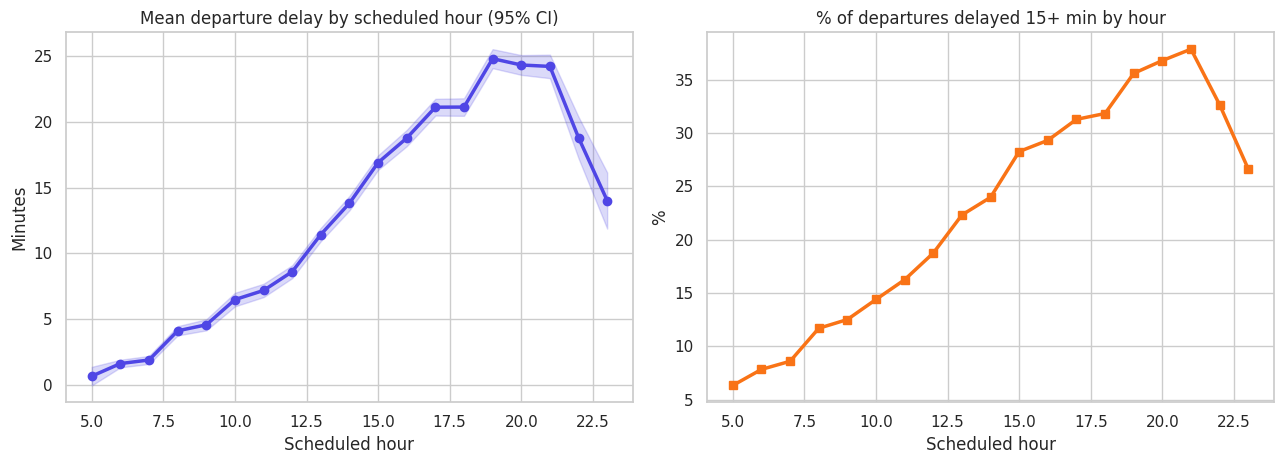

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(hour["hour"], hour["mean_dep"], marker="o", color=PRIMARY, lw=2.5)
axes[0].fill_between(hour["hour"], hour["mean_dep"] - hour["ci"], hour["mean_dep"] + hour["ci"], color=PRIMARY, alpha=0.2)
axes[0].set(title="Mean departure delay by scheduled hour (95% CI)", xlabel="Scheduled hour", ylabel="Minutes")
axes[1].plot(hour["hour"], hour["delayed_pct"], marker="s", color=ACCENT, lw=2.5)
axes[1].set(title="% of departures delayed 15+ min by hour", xlabel="Scheduled hour", ylabel="%")
save(fig, "05_hourly_trend.png")

### 4.5 Seasonality: which months and days are worst?

In [21]:
month = (dep_ok.groupby("month").agg(mean_dep=("dep_delay", "mean"), delayed_pct=("dep_delayed", lambda s: s.mean() * 100)).reset_index())
month["cancel_rate"] = month["month"].map(fl.groupby("month")["is_cancelled"].mean() * 100)
month["cancelled"] = month["month"].map(fl.groupby("month")["is_cancelled"].sum())
month.to_csv(TAB / "monthly_summary.csv", index=False)
mn = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
wd_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = dep_ok.groupby("weekday").agg(mean_dep=("dep_delay", "mean"), delayed_pct=("dep_delayed", lambda s: s.mean() * 100)).reindex(wd_order).reset_index()
season = dep_ok.groupby("season").agg(delayed_pct=("dep_delayed", lambda s: s.mean() * 100), mean_dep=("dep_delay", "mean")).reset_index()
worst_m, best_m = month.loc[month["delayed_pct"].idxmax()], month.loc[month["delayed_pct"].idxmin()]
R["month_table"] = month.round(2).to_dict("records")
R["month"] = {"worst": mn[int(worst_m["month"]) - 1], "worst_pct": float(worst_m["delayed_pct"]), "worst_mean": float(worst_m["mean_dep"]),
              "best": mn[int(best_m["month"]) - 1], "best_pct": float(best_m["delayed_pct"]), "best_mean": float(best_m["mean_dep"])}
R["weekday_table"] = wd.round(2).to_dict("records"); R["season_table"] = season.round(2).to_dict("records")
H3, p_m = stats.kruskal(*[x["dep_delay"].to_numpy() for _, x in dep_ok.groupby("month")])
R["kw_month"] = {"H": float(H3), "p": float(p_m)}
print(f"Kruskal-Wallis across 12 months: H = {H3:,.0f}, p = {p_m:.1e}")
month.round(1)

Kruskal-Wallis across 12 months: H = 8,669, p = 0.0e+00


,month,mean_dep,delayed_pct,cancel_rate,cancelled
0,1,10.00,19.20,1.90,521
1,2,10.80,20.90,5.10,1261
2,3,13.20,22.90,3.00,861
3,4,13.90,23.20,2.40,668
4,5,13.00,23.50,2.00,563
5,6,20.80,29.40,3.60,1009
6,7,21.70,30.30,3.20,940
7,8,12.60,22.90,1.70,486
8,9,6.70,14.40,1.60,452
9,10,6.20,15.40,0.80,236


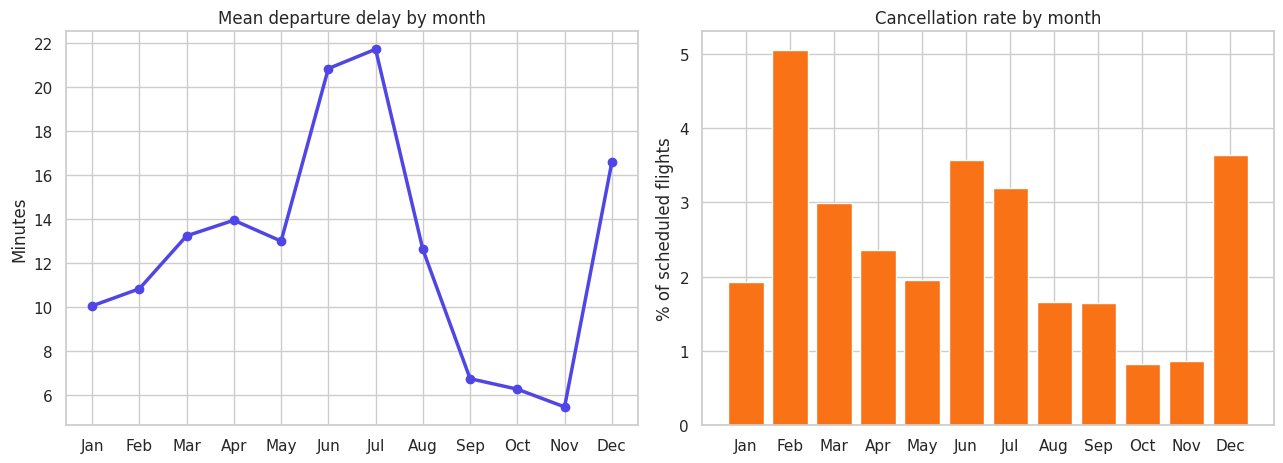

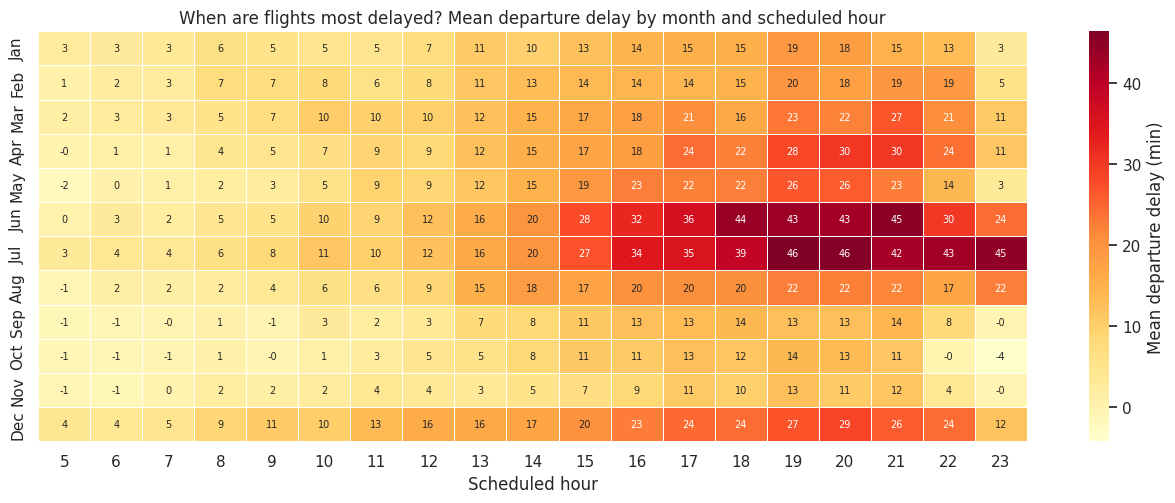

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(mn, month["mean_dep"], marker="o", color=PRIMARY, lw=2.5)
axes[0].set(title="Mean departure delay by month", ylabel="Minutes")
axes[1].bar(mn, month["cancel_rate"], color=ACCENT); axes[1].set(title="Cancellation rate by month", ylabel="% of scheduled flights")
save(fig, "06_monthly_trends.png")

pivot = dep_ok[dep_ok["hour"].between(5, 23)].pivot_table(index="month", columns="hour", values="dep_delay", aggfunc="mean")
pivot.index = mn
fig, ax = plt.subplots(figsize=(13, 5.2))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size": 7}, linewidths=0.4, cbar_kws={"label": "Mean departure delay (min)"}, ax=ax)
ax.set(title="When are flights most delayed? Mean departure delay by month and scheduled hour", xlabel="Scheduled hour", ylabel="")
save(fig, "07_month_hour_heatmap.png")
R["heat_max"] = float(np.nanmax(pivot.values))
hm = pivot.stack().idxmax(); R["heat_max_cell"] = [hm[0], int(hm[1])]
R["heat_min"] = float(np.nanmin(pivot.values))

### 4.6 Delay propagation: how strongly does a late departure become a late arrival?

In [23]:
lr = stats.linregress(arr_ok["dep_delay"], arr_ok["arr_delay"])
rho_p, _ = stats.spearmanr(arr_ok["dep_delay"], arr_ok["arr_delay"])
R["prop"] = {"r": float(lr.rvalue), "r2": float(lr.rvalue ** 2), "slope": float(lr.slope), "intercept": float(lr.intercept),
             "ci_low": float(lr.slope - 1.96 * lr.stderr), "ci_high": float(lr.slope + 1.96 * lr.stderr), "spearman": float(rho_p)}
print(f"arr_delay = {lr.intercept:.2f} + {lr.slope:.3f} x dep_delay | r = {lr.rvalue:.3f}, R2 = {lr.rvalue ** 2:.3f}, Spearman = {rho_p:.3f}")

late_dep = arr_ok[arr_ok["dep_delay"] >= 15]
rec = (late_dep.groupby("dist_band", observed=True)
       .agg(late_departures=("arr_delay", "size"), mean_minutes_gained=("air_gain", "mean"),
            recovered_pct=("arr_delay", lambda s: (s < 15).mean() * 100)).reset_index())
R["recovery_all_pct"] = float((late_dep["arr_delay"] < 15).mean() * 100)
R["recovery_all_gain"] = float(late_dep["air_gain"].mean())
R["late_dep_n"] = int(len(late_dep))
R["recovery_table"] = rec.round(2).to_dict("records")
R["gain_all_mean"] = float(arr_ok["air_gain"].mean())
print(f"\nOf {len(late_dep):,} flights that left 15+ min late, {R['recovery_all_pct']:.1f}% still arrived on time; they gained {R['recovery_all_gain']:.1f} min on average in the air")
rec.round(1)

arr_delay = -5.90 + 1.019 x dep_delay | r = 0.915, R2 = 0.837, Spearman = 0.626

Of 72,420 flights that left 15+ min late, 20.1% still arrived on time; they gained 3.8 min on average in the air


,dist_band,late_departures,mean_minutes_gained,recovered_pct
0,<500 mi,18279,2.40,14.80
1,"500-1,000",24225,2.70,17.60
2,"1,000-2,000",19915,4.50,22.60
3,">2,000 mi",10001,7.60,30.80


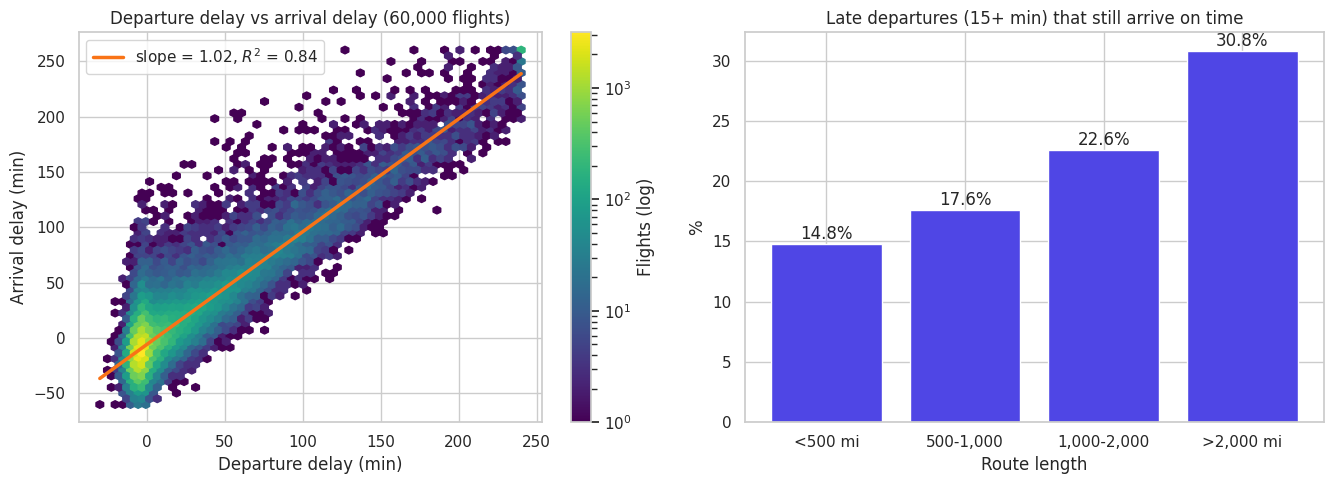

In [24]:
samp = arr_ok.sample(60000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
hb = axes[0].hexbin(samp["dep_delay"].clip(-30, 240), samp["arr_delay"].clip(-60, 260), gridsize=55, bins="log", cmap="viridis", mincnt=1)
xs = np.linspace(-30, 240, 50)
axes[0].plot(xs, lr.intercept + lr.slope * xs, color=ACCENT, lw=2.5, label=f"slope = {lr.slope:.2f}, $R^2$ = {lr.rvalue ** 2:.2f}")
axes[0].set(title="Departure delay vs arrival delay (60,000 flights)", xlabel="Departure delay (min)", ylabel="Arrival delay (min)"); axes[0].legend(loc="upper left")
fig.colorbar(hb, ax=axes[0], label="Flights (log)")
axes[1].bar(rec["dist_band"].astype(str), rec["recovered_pct"], color=PRIMARY)
for i, v in enumerate(rec["recovered_pct"]): axes[1].text(i, v + 0.4, f"{v:.1f}%", ha="center")
axes[1].set(title="Late departures (15+ min) that still arrive on time", xlabel="Route length", ylabel="%")
save(fig, "08_delay_propagation.png")

### 4.7 Weather: how much does it matter?

In [25]:
fl["vis_band"] = pd.cut(fl["visib"], [-0.01, 1, 3, 6, 9.99, 10], labels=["<=1 mi", "1-3 mi", "3-6 mi", "6-10 mi", "10 mi (clear)"])
dep_ok = fl[fl["dep_delay"].notna()].copy(); arr_ok = fl[fl["status"] == "Completed"].copy()
dw = dep_ok[dep_ok["visib"].notna()].copy()

vis = dw.groupby("vis_band", observed=True).agg(flights=("dep_delay", "size"), mean_dep=("dep_delay", "mean"),
                                                 delayed_pct=("dep_delayed", lambda s: s.mean() * 100)).reset_index()
vis["cancel_rate"] = vis["vis_band"].map(fl[fl["visib"].notna()].groupby("vis_band", observed=True)["is_cancelled"].mean().mul(100).to_dict())
R["vis_table"] = vis.round(2).to_dict("records")

rain = dw["precip"] > 0
x, y = dw.loc[rain, "dep_delay"], dw.loc[~rain, "dep_delay"]
U, p_mw = stats.mannwhitneyu(x, y, alternative="two-sided")
cles = U / (len(x) * len(y))                     # probability that a random rainy flight is later than a random dry flight
a1, n1 = int(dw.loc[rain, "dep_delayed"].sum()), int(rain.sum()); a0, n0 = int(dw.loc[~rain, "dep_delayed"].sum()), int((~rain).sum())
rr = (a1 / n1) / (a0 / n0); se = np.sqrt(1 / a1 - 1 / n1 + 1 / a0 - 1 / n0)
R["rain"] = {"n_rain": n1, "n_dry": n0, "pct_rain": a1 / n1 * 100, "pct_dry": a0 / n0 * 100, "median_rain": float(x.median()), "median_dry": float(y.median()),
             "mean_rain": float(x.mean()), "mean_dry": float(y.mean()), "mw_p": float(p_mw), "cles": float(cles), "rr": float(rr),
             "rr_low": float(np.exp(np.log(rr) - 1.96 * se)), "rr_high": float(np.exp(np.log(rr) + 1.96 * se))}
cold, windy = dw["temp"] < 32, dw["wind_speed"] >= 20
R["cold_pct"], R["cold_n"] = float(dw.loc[cold, "dep_delayed"].mean() * 100), int(cold.sum())
R["windy_pct"], R["windy_n"] = float(dw.loc[windy, "dep_delayed"].mean() * 100), int(windy.sum())
R["calm_pct"] = float(dw.loc[~windy, "dep_delayed"].mean() * 100)
R["weather_spearman"] = {c: float(stats.spearmanr(dw[c], dw["dep_delay"])[0]) for c in ["temp", "humid", "wind_speed", "visib", "precip"]}
print(f"Rain/precip: {R['rain']['pct_rain']:.1f}% delayed vs {R['rain']['pct_dry']:.1f}% dry | relative risk = {rr:.2f} (95% CI {R['rain']['rr_low']:.2f}-{R['rain']['rr_high']:.2f}) | Mann-Whitney p = {p_mw:.1e}, CLES = {cles:.3f}")
print("Spearman correlation with departure delay:", {k: round(v, 3) for k, v in R["weather_spearman"].items()})
vis.round(1)

Rain/precip: 40.0% delayed vs 21.0% dry | relative risk = 1.91 (95% CI 1.87-1.94) | Mann-Whitney p = 0.0e+00, CLES = 0.636
Spearman correlation with departure delay: {'temp': 0.049, 'humid': 0.094, 'wind_speed': 0.063, 'visib': -0.084, 'precip': 0.116}


,vis_band,flights,mean_dep,delayed_pct,cancel_rate
0,<=1 mi,4963,30.40,35.90,8.92
1,1-3 mi,10426,23.20,33.50,7.84
2,3-6 mi,12639,20.20,29.50,5.13
3,6-10 mi,25305,19.20,26.90,4.14
4,10 mi (clear),273660,11.00,20.70,1.82


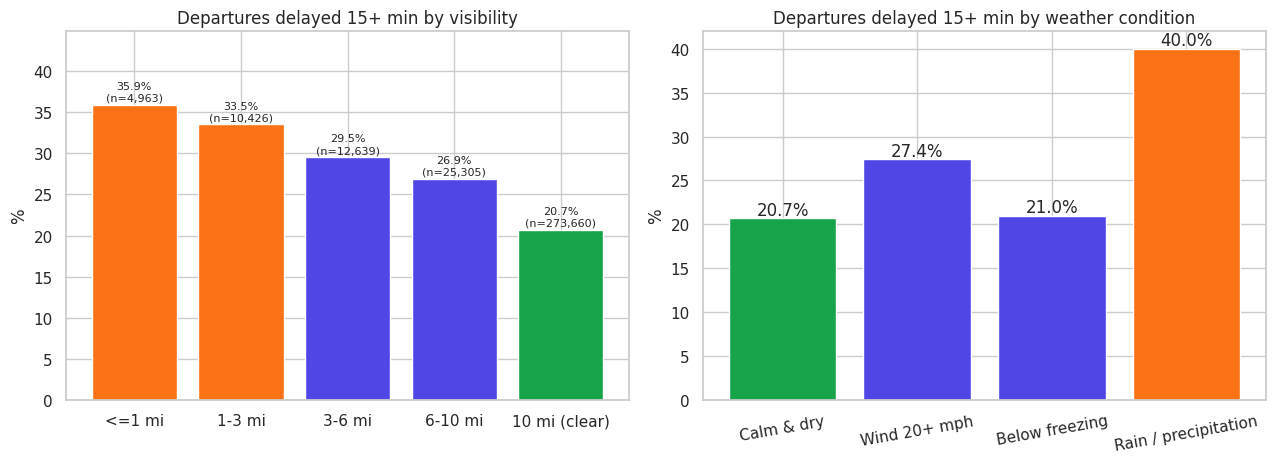

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(vis["vis_band"].astype(str), vis["delayed_pct"], color=[ACCENT, ACCENT, PRIMARY, PRIMARY, GREEN])
for i, (v, n) in enumerate(zip(vis["delayed_pct"], vis["flights"])): axes[0].text(i, v + 0.5, f"{v:.1f}%\n(n={n:,})", ha="center", fontsize=8)
axes[0].set(title="Departures delayed 15+ min by visibility", ylabel="%", ylim=(0, vis["delayed_pct"].max() * 1.25))
cats = ["Calm & dry", "Wind 20+ mph", "Below freezing", "Rain / precipitation"]
vals = [dw.loc[~windy & ~rain, "dep_delayed"].mean() * 100, R["windy_pct"], R["cold_pct"], R["rain"]["pct_rain"]]
axes[1].bar(cats, vals, color=[GREEN, PRIMARY, PRIMARY, ACCENT])
for i, v in enumerate(vals): axes[1].text(i, v + 0.4, f"{v:.1f}%", ha="center")
axes[1].set(title="Departures delayed 15+ min by weather condition", ylabel="%"); plt.setp(axes[1].get_xticklabels(), rotation=10)
save(fig, "09_weather_effects.png")

### 4.8 Cancellations

In [27]:
daily = fl.groupby("date").agg(cancelled=("is_cancelled", "sum"), scheduled=("is_cancelled", "size"))
top = daily.nlargest(5, "cancelled"); total_c = int(fl["is_cancelled"].sum())
R["top_cancel_days"] = [{"date": d.strftime("%d %b %Y"), "cancelled": int(r.cancelled), "scheduled": int(r.scheduled), "pct": float(r.cancelled / r.scheduled * 100)} for d, r in top.iterrows()]
R["top5_cancel_share"] = float(top["cancelled"].sum() / total_c * 100); R["top2_cancel_share"] = float(top["cancelled"].head(2).sum() / total_c * 100)
R["median_daily_cancel"] = float(daily["cancelled"].median())
big = daily[daily["cancelled"] >= 50]
R["days_ge50"], R["n_days"] = int(len(big)), int(len(daily))
R["days_ge50_share"] = float(big["cancelled"].sum() / total_c * 100)
R["days_ge50_pct_of_year"] = float(len(big) / len(daily) * 100)
print(f"Days with 50+ cancellations (about 7x a typical day): {len(big)} of {len(daily)} days ({len(big) / len(daily):.1%}) hold {R['days_ge50_share']:.1f}% of all cancellations")

fw = fl[fl["precip"].notna()]; r_ = fw["precip"] > 0
tab = pd.crosstab(r_, fw["is_cancelled"]); chi2, p_chi, _, _ = stats.chi2_contingency(tab)
c1, m1 = int(fw.loc[r_, "is_cancelled"].sum()), int(r_.sum()); c0, m0 = int(fw.loc[~r_, "is_cancelled"].sum()), int((~r_).sum())
rr_c = (c1 / m1) / (c0 / m0); se_c = np.sqrt(1 / c1 - 1 / m1 + 1 / c0 - 1 / m0)
R["cancel_rain"] = {"rate_rain": c1 / m1 * 100, "rate_dry": c0 / m0 * 100, "rr": float(rr_c), "rr_low": float(np.exp(np.log(rr_c) - 1.96 * se_c)),
                    "rr_high": float(np.exp(np.log(rr_c) + 1.96 * se_c)), "chi2": float(chi2), "p": float(p_chi)}
print(f"Total cancelled: {total_c:,} | top-5 days = {R['top5_cancel_share']:.1f}% of all cancellations | typical day = {R['median_daily_cancel']:.0f}")
print(f"Cancel rate: rain {c1 / m1:.2%} vs dry {c0 / m0:.2%} | RR = {rr_c:.2f} (95% CI {R['cancel_rain']['rr_low']:.2f}-{R['cancel_rain']['rr_high']:.2f}) | chi2 p = {p_chi:.1e}")
pd.DataFrame(R["top_cancel_days"])

Days with 50+ cancellations (about 7x a typical day): 48 of 365 days (13.2%) hold 63.2% of all cancellations
Total cancelled: 8,255 | top-5 days = 18.0% of all cancellations | typical day = 7
Cancel rate: rain 8.33% vs dry 2.02% | RR = 4.12 (95% CI 3.92-4.33) | chi2 p = 0.0e+00


,date,cancelled,scheduled,pct
0,08 Feb 2013,472,930,50.75
1,09 Feb 2013,393,684,57.46
2,23 May 2013,221,988,22.37
3,10 Dec 2013,204,943,21.63
4,12 Sep 2013,192,992,19.35


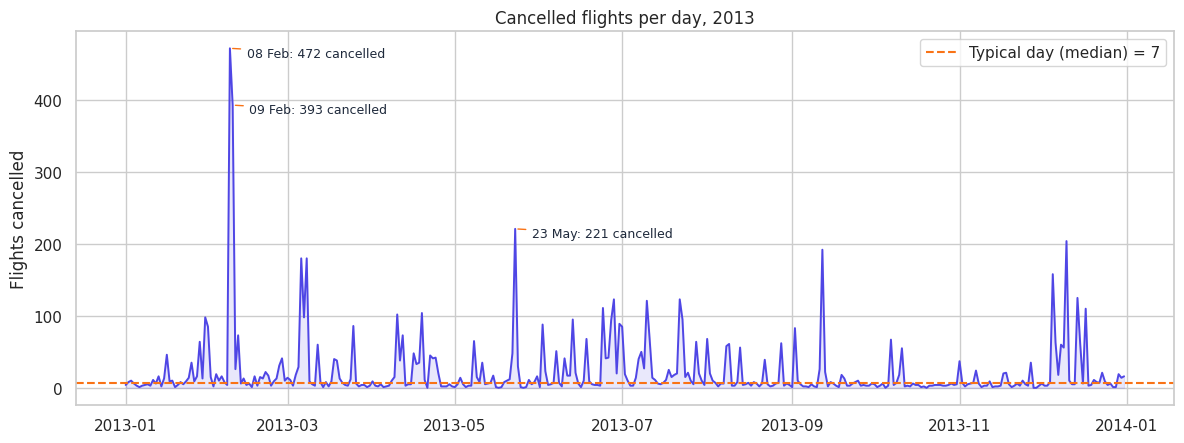

In [28]:
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(daily.index, daily["cancelled"], color=PRIMARY, lw=1.4)
ax.fill_between(daily.index, daily["cancelled"], color=PRIMARY, alpha=0.12)
for d, r in top.head(3).iterrows():
    ax.annotate(f"{d:%d %b}: {int(r.cancelled)} cancelled", (d, r.cancelled), xytext=(12, -6), textcoords="offset points", fontsize=9, color=DARK,
                arrowprops=dict(arrowstyle="-", color=ACCENT))
ax.axhline(R["median_daily_cancel"], color=ACCENT, ls="--", label=f"Typical day (median) = {R['median_daily_cancel']:.0f}"); ax.legend()
ax.set(title="Cancelled flights per day, 2013", ylabel="Flights cancelled")
save(fig, "10_daily_cancellations.png")

### 4.9 Things that do NOT matter much (negative findings are findings too)

Aircraft age vs arrival delay: Spearman rho = -0.025 (p = 1.1e-37, n = 273,853) -> rho^2 = 0.0006


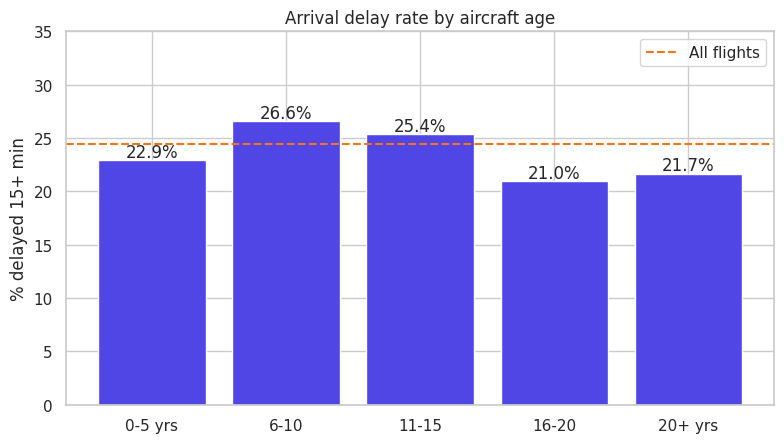

,age_band,flights,mean_arr,delayed_pct
0,0-5 yrs,45889,4.90,22.90
1,6-10,72056,9.40,26.60
2,11-15,107120,7.90,25.40
3,16-20,15110,3.20,21.00
4,20+ yrs,33678,3.90,21.70


In [29]:
fl["age_band"] = pd.cut(fl["aircraft_age"], [-1, 5, 10, 15, 20, 60], labels=["0-5 yrs", "6-10", "11-15", "16-20", "20+ yrs"])
arr_ok = fl[fl["status"] == "Completed"].copy()
age = arr_ok.groupby("age_band", observed=True).agg(flights=("arr_delay", "size"), mean_arr=("arr_delay", "mean"), delayed_pct=("arr_delayed", lambda s: s.mean() * 100)).reset_index()
a_ok = arr_ok[arr_ok["aircraft_age"].notna()]
rho_a, p_a = stats.spearmanr(a_ok["aircraft_age"], a_ok["arr_delay"])
R["age"] = {"rho": float(rho_a), "p": float(p_a), "n": int(len(a_ok)), "min_pct": float(age["delayed_pct"].min()), "max_pct": float(age["delayed_pct"].max())}
R["age_table"] = age.round(2).to_dict("records")
print(f"Aircraft age vs arrival delay: Spearman rho = {rho_a:.3f} (p = {p_a:.1e}, n = {len(a_ok):,}) -> rho^2 = {rho_a ** 2:.4f}")
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.bar(age["age_band"].astype(str), age["delayed_pct"], color=PRIMARY)
for i, v in enumerate(age["delayed_pct"]): ax.text(i, v + 0.3, f"{v:.1f}%", ha="center")
ax.axhline(R["overall"]["arr_delayed_pct"], color=ACCENT, ls="--", label="All flights"); ax.legend()
ax.set(title="Arrival delay rate by aircraft age", ylabel="% delayed 15+ min", ylim=(0, 35))
save(fig, "11_aircraft_age.png")
age.round(1)

### 4.10 Routes and correlation overview

Busiest destinations
dest                            airport  flights  mean_arr  delayed_pct
 ATL    Hartsfield Jackson Atlanta Intl    16837     11.30        26.20
 ORD                 Chicago Ohare Intl    16566      5.90        24.00
 LAX                   Los Angeles Intl    16026      0.50        21.00
 BOS General Edward Lawrence Logan Intl    15022      2.90        19.00
 MCO                       Orlando Intl    13967      5.50        22.90

Worst delay rates (1,000+ flights)
dest                           airport  flights  mean_arr  delayed_pct
 RIC                     Richmond Intl     2346     20.10        36.60
 MCI                  Kansas City Intl     1885     14.50        32.60
 GSO                    Piedmont Triad     1492     14.10        31.40
 JAX                 Jacksonville Intl     2623     11.80        30.20
 CVG Cincinnati Northern Kentucky Intl     3725     15.40        30.20


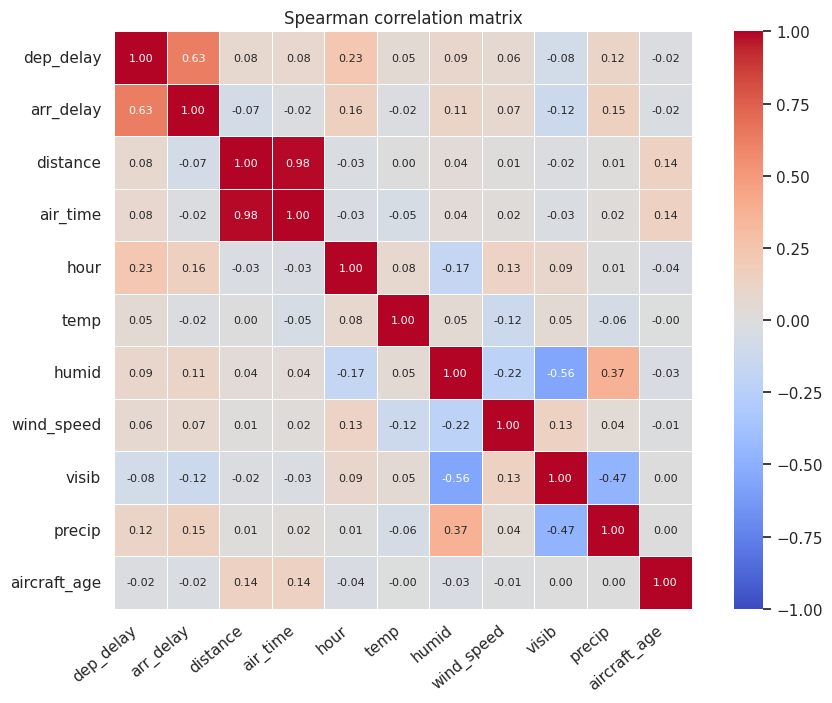

In [30]:
dest = (arr_ok.groupby("dest", observed=True).agg(flights=("arr_delay", "size"), mean_arr=("arr_delay", "mean"), delayed_pct=("arr_delayed", lambda s: s.mean() * 100)).reset_index())
dest["dest"] = dest["dest"].astype(str)
dest = dest.merge(airports[["faa", "name"]].rename(columns={"faa": "dest", "name": "airport"}), on="dest", how="left")
busiest = dest.nlargest(5, "flights"); worst = dest[dest["flights"] >= 1000].nlargest(5, "delayed_pct"); best = dest[dest["flights"] >= 1000].nsmallest(3, "delayed_pct")
R["busiest_dest"] = busiest.round(2).to_dict("records"); R["worst_dest"] = worst.round(2).to_dict("records"); R["best_dest"] = best.round(2).to_dict("records")
print("Busiest destinations"); print(busiest[["dest", "airport", "flights", "mean_arr", "delayed_pct"]].round(1).to_string(index=False))
print("\nWorst delay rates (1,000+ flights)"); print(worst[["dest", "airport", "flights", "mean_arr", "delayed_pct"]].round(1).to_string(index=False))

num_cols = ["dep_delay", "arr_delay", "distance", "air_time", "hour", "temp", "humid", "wind_speed", "visib", "precip", "aircraft_age"]
corr = arr_ok[num_cols].corr(method="spearman")
R["corr_dep_arr"] = float(corr.loc["dep_delay", "arr_delay"]); R["corr_dist_air"] = float(corr.loc["distance", "air_time"])
fig, ax = plt.subplots(figsize=(9.5, 7.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.4, annot_kws={"size": 8}, ax=ax)
ax.set_title("Spearman correlation matrix"); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
save(fig, "12_correlation_heatmap.png")

## 5. Statistical modelling: can delay risk be predicted *before* departure?

**Design choices (and why)**
- **Target:** `arr_delayed` (arrival 15+ min late), a yes/no outcome, so **logistic regression** is the natural, interpretable starting point.
- **Features:** only things known **before** the flight leaves: scheduled hour, month, weekday, airport, airline, distance, weather at departure, aircraft age. `dep_delay` is **deliberately excluded**, because it would be *data leakage* (it is only known after the flight is already late).
- **Evaluation:** a **stratified 80/20 train-test split** (seed 42). The model is judged on the 20% it never saw, using **AUC** (0.5 = coin flip, 1.0 = perfect) and compared with a "always predict on time" baseline.
- **Second opinion:** a gradient-boosting model checks whether non-linear patterns add much, and **permutation importance** shows which feature groups matter.

In [31]:
mdl = arr_ok.dropna(subset=["temp", "humid", "wind_speed", "visib", "precip"]).copy()
R["model_rows"], R["model_dropped"] = int(len(mdl)), int(len(arr_ok) - len(mdl))
mdl["rain"] = (mdl["precip"] > 0).astype(int)
mdl["age_missing"] = mdl["aircraft_age"].isna().astype(int)
mdl["age_filled"] = mdl["aircraft_age"].fillna(mdl["aircraft_age"].median())
mdl["distance_k"] = mdl["distance"] / 1000
mdl["y"] = mdl["arr_delayed"].astype(int)
for c in ["origin", "carrier", "weekday"]: mdl[c] = mdl[c].astype(str)
mdl["month"] = mdl["month"].astype(str)

num = ["hour", "distance_k", "temp", "humid", "wind_speed", "visib", "rain", "age_filled", "age_missing"]
X = pd.get_dummies(mdl[num + ["month", "weekday", "origin", "carrier"]], columns=["month", "weekday", "origin", "carrier"], dtype=float)
X = X.drop(columns=["month_1", "weekday_Monday", "origin_EWR", "carrier_UA"])   # reference groups
X_train, X_test, y_train, y_test = train_test_split(X, mdl["y"], test_size=0.2, stratify=mdl["y"], random_state=SEED)

logit = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0, maxiter=200)
p_test = logit.predict(sm.add_constant(X_test))
auc_logit = roc_auc_score(y_test, p_test)
base_rate = float(y_test.mean())
R["model"] = {"n_train": int(len(X_train)), "n_test": int(len(X_test)), "n_features": int(X.shape[1]), "base_rate": base_rate * 100,
              "baseline_acc": (1 - base_rate) * 100, "acc_05": float(accuracy_score(y_test, p_test >= 0.5) * 100), "auc_logit": float(auc_logit),
              "pseudo_r2": float(logit.prsquared)}
dec = pd.DataFrame({"p": p_test, "y": y_test}); dec["decile"] = pd.qcut(dec["p"].rank(method="first"), 10, labels=range(1, 11))
dec_t = dec.groupby("decile", observed=True)["y"].mean() * 100
R["model"].update({"top_decile_rate": float(dec_t.iloc[-1]), "bottom_decile_rate": float(dec_t.iloc[0]), "lift_top": float(dec_t.iloc[-1] / (base_rate * 100))})

odds = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(logit.conf_int()[0]), "ci_high": np.exp(logit.conf_int()[1]), "p": logit.pvalues}).drop(index="const")
odds.to_csv(TAB / "logistic_odds_ratios.csv")
labels = {"hour": "Each later scheduled hour", "distance_k": "Each extra 1,000 miles", "temp": "Each +10 F temperature", "humid": "Each +10% humidity", "wind_speed": "Each +5 mph wind",
          "visib": "Each +1 mile visibility", "rain": "Rain / precipitation (yes vs no)", "age_filled": "Each +5 years aircraft age", "origin_JFK": "JFK (vs Newark)", "origin_LGA": "LaGuardia (vs Newark)"}
sel = odds.loc[list(labels)].copy(); sel["label"] = [labels[i] for i in sel.index]
for k_, f_ in {"temp": 10, "humid": 10, "wind_speed": 5, "age_filled": 5}.items():   # rescale to meaningful units
    sel.loc[k_, ["odds_ratio", "ci_low", "ci_high"]] = sel.loc[k_, ["odds_ratio", "ci_low", "ci_high"]].astype(float) ** f_
R["or_table"] = sel.reset_index(drop=True).round(4).to_dict("records")
car = odds[odds.index.str.startswith("carrier_")]; R["or_carrier_best"] = {"name": car["odds_ratio"].idxmin(), **car.loc[car["odds_ratio"].idxmin()].round(3).to_dict()}
R["or_carrier_worst"] = {"name": car["odds_ratio"].idxmax(), **car.loc[car["odds_ratio"].idxmax()].round(3).to_dict()}
print(f"Logistic regression | train {len(X_train):,} / test {len(X_test):,} | features {X.shape[1]} | pseudo R2 = {logit.prsquared:.3f}")
print(f"Test AUC = {auc_logit:.3f} | base delay rate = {base_rate:.1%} | baseline accuracy = {1 - base_rate:.1%} | accuracy at 0.5 = {R['model']['acc_05']:.1f}%")
print(f"Top-decile predicted risk -> {R['model']['top_decile_rate']:.1f}% actually delayed vs bottom decile {R['model']['bottom_decile_rate']:.1f}% (lift {R['model']['lift_top']:.2f}x)")
sel[["label", "odds_ratio", "ci_low", "ci_high", "p"]].round(4)

Logistic regression | train 260,655 / test 65,164 | features 43 | pseudo R2 = 0.100
Test AUC = 0.717 | base delay rate = 24.5% | baseline accuracy = 75.5% | accuracy at 0.5 = 77.1%
Top-decile predicted risk -> 57.8% actually delayed vs bottom decile 8.4% (lift 2.36x)


,label,odds_ratio,ci_low,ci_high,p
hour,Each later scheduled hour,1.12,1.11,1.12,0.00
distance_k,"Each extra 1,000 miles",1.06,1.04,1.08,0.00
temp,Each +10 F temperature,1.04,1.02,1.05,0.00
humid,Each +10% humidity,1.15,1.14,1.15,0.00
wind_speed,Each +5 mph wind,1.20,1.19,1.21,0.00
visib,Each +1 mile visibility,0.94,0.93,0.94,0.00
rain,Rain / precipitation (yes vs no),1.59,1.53,1.66,0.00
age_filled,Each +5 years aircraft age,1.06,1.05,1.08,0.00
origin_JFK,JFK (vs Newark),0.76,0.73,0.79,0.00
origin_LGA,LaGuardia (vs Newark),0.95,0.93,0.98,0.00


In [32]:
Xh = mdl[["hour", "distance", "temp", "humid", "wind_speed", "visib", "precip", "aircraft_age", "month", "weekday", "origin", "carrier"]].copy()
for c in ["month", "weekday", "origin", "carrier"]: Xh[c] = Xh[c].astype("category")
Xh_tr, Xh_te = Xh.loc[X_train.index], Xh.loc[X_test.index]
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, categorical_features="from_dtype", random_state=SEED).fit(Xh_tr, y_train)
p_h = hgb.predict_proba(Xh_te)[:, 1]; auc_h = roc_auc_score(y_test, p_h)
R["model"]["auc_hgb"] = float(auc_h)

sub = Xh_te.sample(20000, random_state=SEED); ysub = y_test.loc[sub.index]
perm = permutation_importance(hgb, sub, ysub, scoring="roc_auc", n_repeats=3, random_state=SEED)
imp = pd.Series(perm.importances_mean, index=Xh.columns).sort_values(ascending=False)
nice = {"hour": "Scheduled hour", "month": "Month", "carrier": "Airline", "origin": "Airport", "distance": "Distance", "weekday": "Weekday", "visib": "Visibility",
        "wind_speed": "Wind speed", "temp": "Temperature", "humid": "Humidity", "precip": "Precipitation", "aircraft_age": "Aircraft age"}
R["importance"] = [{"feature": nice[k], "auc_drop": float(v)} for k, v in imp.items()]
print(f"Gradient boosting test AUC = {auc_h:.3f} (logistic = {auc_logit:.3f})")
print((imp.rename(index=nice) * 1).round(4).to_string())

Gradient boosting test AUC = 0.777 (logistic = 0.717)
Scheduled hour   0.11
Month            0.06
Humidity         0.06
Weekday          0.04
Airline          0.04
Temperature      0.03
Distance         0.01
Wind speed       0.01
Airport          0.01
Precipitation    0.01
Visibility       0.00
Aircraft age     0.00


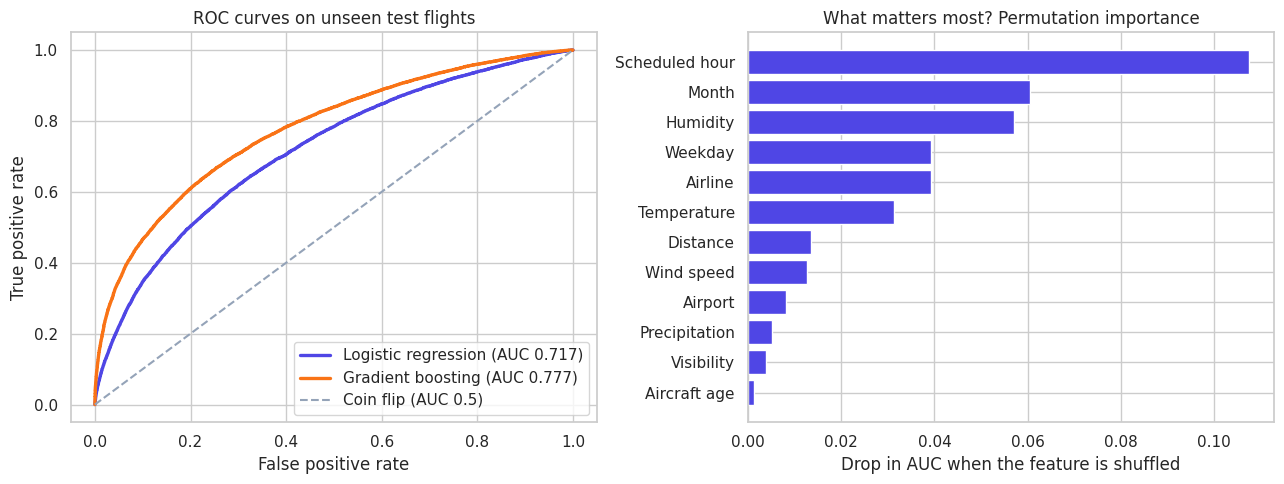

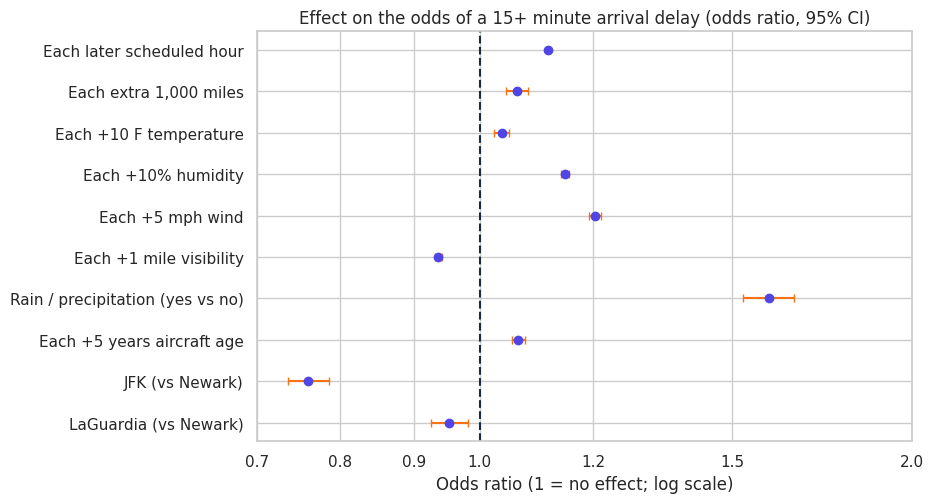

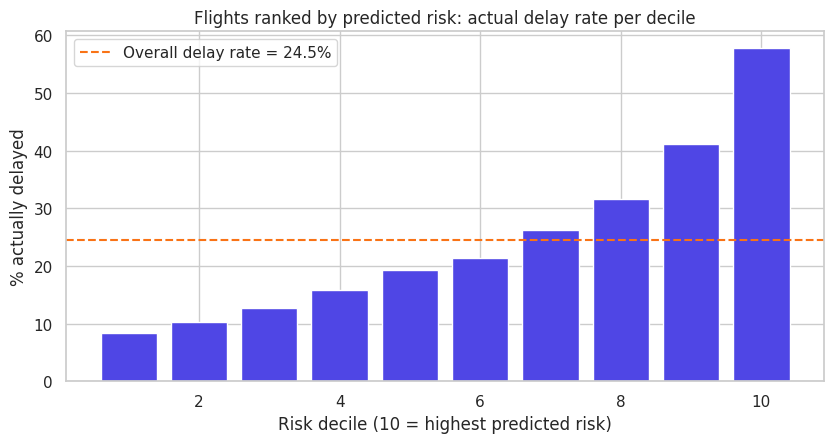

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for p_, lab, col in [(p_test, f"Logistic regression (AUC {auc_logit:.3f})", PRIMARY), (p_h, f"Gradient boosting (AUC {auc_h:.3f})", ACCENT)]:
    fpr, tpr, _ = roc_curve(y_test, p_); axes[0].plot(fpr, tpr, color=col, lw=2.4, label=lab)
axes[0].plot([0, 1], [0, 1], color="#94A3B8", ls="--", label="Coin flip (AUC 0.5)")
axes[0].set(title="ROC curves on unseen test flights", xlabel="False positive rate", ylabel="True positive rate"); axes[0].legend(loc="lower right")
ii = imp.rename(index=nice).sort_values()
axes[1].barh(ii.index, ii.values, color=PRIMARY); axes[1].set(title="What matters most? Permutation importance", xlabel="Drop in AUC when the feature is shuffled")
save(fig, "13_model_roc_importance.png")

fig, ax = plt.subplots(figsize=(9.5, 5.2))
s2 = sel.iloc[::-1]
ax.errorbar(s2["odds_ratio"], range(len(s2)), xerr=[s2["odds_ratio"] - s2["ci_low"], s2["ci_high"] - s2["odds_ratio"]], fmt="o", color=PRIMARY, ecolor=ACCENT, capsize=3)
ax.axvline(1, color=DARK, ls="--"); ax.set_yticks(range(len(s2))); ax.set_yticklabels(s2["label"]); ax.set_xscale("log")
ax.set_xticks([0.7, 0.8, 0.9, 1, 1.2, 1.5, 2]); ax.xaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter()); ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set(title="Effect on the odds of a 15+ minute arrival delay (odds ratio, 95% CI)", xlabel="Odds ratio (1 = no effect; log scale)")
save(fig, "14_odds_ratios.png")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.bar(dec_t.index.astype(int), dec_t.values, color=PRIMARY); ax.axhline(base_rate * 100, color=ACCENT, ls="--", label=f"Overall delay rate = {base_rate:.1%}"); ax.legend()
ax.set(title="Flights ranked by predicted risk: actual delay rate per decile", xlabel="Risk decile (10 = highest predicted risk)", ylabel="% actually delayed")
save(fig, "15_risk_deciles.png")

## 6. Key insights with the numbers behind them

In [34]:
o, h, m, pr, rn, cr = R["overall"], R["hour"], R["month"], R["prop"], R["rain"], R["cancel_rain"]
top_c, bot_c = R["carrier_table"][0], R["carrier_table"][-1]
age_or = next(x for x in R["or_table"] if x["label"].startswith("Each +5 years"))
R["age_adj_or"] = age_or
big_c = pd.DataFrame(R["carrier_table"]).query("flights >= 10000").sort_values("pct_delayed", ascending=False)
R["carrier_big"] = {"worst": big_c.iloc[0]["airline"], "worst_pct": float(big_c.iloc[0]["pct_delayed"]), "best": big_c.iloc[-1]["airline"], "best_pct": float(big_c.iloc[-1]["pct_delayed"]), "n": int(len(big_c))}
ewr = next(x for x in R["origin_table"] if x["origin"] == "EWR"); lga = next(x for x in R["origin_table"] if x["origin"] == "LGA")
lines = [
 f"1. SCALE: {o['dep_delayed_pct']:.1f}% of departures and {o['arr_delayed_pct']:.1f}% of arrivals are 15+ min late; {o['cancel_rate']:.2f}% of flights are cancelled ({R['status_counts']['Cancelled']:,}).",
 f"2. SKEW: mean arrival delay = {o['arr_mean']:.1f} min but median = {o['arr_median']:.0f} min; the worst 10% of late flights account for {o['top10pct_share_of_delay_minutes']:.0f}% of all delay minutes.",
 f"3. AIRLINES: among the {len(big_c)} carriers with 10,000+ flights the arrival-delay rate ranges from {big_c.iloc[-1]['pct_delayed']:.1f}% ({big_c.iloc[-1]['airline']}) to {big_c.iloc[0]['pct_delayed']:.1f}% ({big_c.iloc[0]['airline']}); Kruskal-Wallis H = {R['kw_carrier']['H']:,.0f}, p < 0.001, epsilon-squared = {R['kw_carrier']['epsilon2']:.3f} (a SMALL effect by convention, yet a large practical gap between best and worst).",
 f"4. AIRPORTS: Newark has the highest departure-delay rate ({ewr['dep_delayed_pct']:.1f}%) vs LaGuardia ({lga['dep_delayed_pct']:.1f}%), BUT LaGuardia has the highest cancellation rate ({lga['cancel_rate']:.2f}% vs {ewr['cancel_rate']:.2f}% at Newark): cancelled flights vanish from delay statistics (survivorship bias).",
 f"5. TIME OF DAY: {h['early_pct']:.1f}% of departures up to 8am are delayed vs {h['evening_pct']:.1f}% for 5-8pm; peak hour {h['peak_hour']}:00 reaches {h['peak_pct']:.1f}% (Spearman rho = {h['rho']:.2f}).",
 f"6. SEASON: worst month {m['worst']} ({m['worst_pct']:.1f}% delayed), best {m['best']} ({m['best_pct']:.1f}%).",
 f"7. PROPAGATION: each extra minute of departure delay adds {pr['slope']:.2f} min to the arrival delay (R-squared = {pr['r2']:.2f}); only {R['recovery_all_pct']:.1f}% of late departures arrive on time.",
 f"8. WEATHER: precipitation raises the delay rate from {rn['pct_dry']:.1f}% to {rn['pct_rain']:.1f}% (relative risk {rn['rr']:.2f}, 95% CI {rn['rr_low']:.2f}-{rn['rr_high']:.2f}) and cancellations {cr['rr']:.1f}x.",
 f"9. CANCELLATIONS ARE CONCENTRATED: just {R['days_ge50']} days ({R['days_ge50_pct_of_year']:.0f}% of the year, each with 50+ cancellations) hold {R['days_ge50_share']:.0f}% of all cancellations; a typical day has {R['median_daily_cancel']:.0f}. The two worst days (8-9 Feb) alone hold {R['top2_cancel_share']:.1f}%.",
 f"10. AIRCRAFT AGE SHOWS NO CONSISTENT EFFECT: Spearman rho = {R['age']['rho']:.3f} (explains {R['age']['rho'] ** 2 * 100:.2f}% of rank variation); age groups range from {R['age']['min_pct']:.1f}% to {R['age']['max_pct']:.1f}% delayed without a trend. After adjusting for airline, airport and hour the effect is small but positive (odds ratio {age_or['odds_ratio']:.2f} per 5 years, 95% CI {age_or['ci_low']:.2f}-{age_or['ci_high']:.2f}): the raw and adjusted views differ because older aircraft are concentrated in certain airlines (confounding).",
 f"11. PREDICTABILITY: AUC = {R['model']['auc_logit']:.3f} (logistic) / {R['model']['auc_hgb']:.3f} (boosting); top-risk decile is delayed {R['model']['top_decile_rate']:.1f}% of the time vs {R['model']['bottom_decile_rate']:.1f}% for the lowest decile.",
]
print("\n".join(lines))

1. SCALE: 22.2% of departures and 24.5% of arrivals are 15+ min late; 2.45% of flights are cancelled (8,255).
2. SKEW: mean arrival delay = 6.9 min but median = -5 min; the worst 10% of late flights account for 41% of all delay minutes.
3. AIRLINES: among the 9 carriers with 10,000+ flights the arrival-delay rate ranges from 18.8% (US Airways Inc.) to 32.1% (ExpressJet Airlines Inc.); Kruskal-Wallis H = 8,565, p < 0.001, epsilon-squared = 0.026 (a SMALL effect by convention, yet a large practical gap between best and worst).
4. AIRPORTS: Newark has the highest departure-delay rate (25.3%) vs LaGuardia (19.5%), BUT LaGuardia has the highest cancellation rate (3.01% vs 2.68% at Newark): cancelled flights vanish from delay statistics (survivorship bias).
5. TIME OF DAY: 9.4% of departures up to 8am are delayed vs 33.6% for 5-8pm; peak hour 21:00 reaches 37.8% (Spearman rho = 0.23).
6. SEASON: worst month Jul (30.3% delayed), best Sep (14.4%).
7. PROPAGATION: each extra minute of departure

## 7. Recommendations (each tied to evidence above)

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Protect the morning departure banks** and add buffer to late-evening schedules | Delay rate rises steadily through the day (insight 5) |
| 2 | **Prevent the first delay** (fast turnarounds, crew/gate readiness) because delays are almost one-for-one carried to arrival | Slope close to 1, only a minority of late flights recover (insight 7) |
| 3 | **Pre-plan for precipitation and low visibility**: stage de-icing/ground crews and proactively rebook | Relative risk of delay and cancellation (insight 8) |
| 4 | **Treat cancellations as event management**: a minority of days (about 1 in 8) account for most cancellations, so invest in extreme-event playbooks (de-icing, rebooking, crew repositioning) | Concentration of cancellations on 50+ cancellation days (insight 9) |
| 5 | **Benchmark airlines and Newark** and investigate root causes at the worst performers | Significant, moderate differences (insights 3, 4) |
| 6 | **Do not use aircraft age as a delay lever or predictor** | No consistent age trend (insight 10) |
| 7 | **Use the risk model to flag high-risk flights** a day ahead for extra buffer or rebooking | Top decile vs bottom decile delay rates (insight 11) |

## 8. Limitations and potential biases (honest assessment)

| Limitation / bias | What it means here | Effect on conclusions and how I handled it |
|---|---|---|
| **One year, three airports** | Only 2013 and JFK/LGA/EWR. Two February days alone hold about 10% of the year's cancellations | Findings may not hold in other years or airports; cancellation patterns are described as event-driven, not general |
| **Dated data** | 2013 is more than a decade old; airline mergers, new technology and schedule changes since then are not reflected | Treat results as a method demonstration and a historical benchmark |
| **Departure-only sampling** | Only flights *leaving* New York are included, so arrival-side congestion at New York is not covered | Statements about "airports" mean departure airports only |
| **Cancelled and diverted flights excluded from delay statistics** | They have no delay value, which is a form of **survivorship bias**: the worst-affected flights disappear from delay averages | Cancellations analysed separately; delay results describe flights that completed |
| **Delay cause is unknown** | The table has no cause codes (airline, weather, air-traffic control, late aircraft) | Weather effects are inferred from matched weather, not from official causes; the model explains only part of the risk |
| **Weather is measured at the airport, hourly** | The weather at the destination, on the route and within the hour are not captured; 165 airport-hours are missing | Weather effects are probably underestimated (measurement error biases effects toward zero) |
| **Missing and imputed values** | Short weather gaps (3,197 values) were interpolated; about 17% of flights have no aircraft age; wind gusts are missing in about 80% of hours and were excluded | Only gaps of up to 6 hours were filled; aircraft age is flagged in the model; variables with large gaps were not used |
| **Heavy tails and outliers** | The longest delay is over 21 hours; the IQR rule flags many large delays | Genuine events were kept; robust and rank-based methods used so that results do not depend on a few extreme values |
| **Statistical vs practical significance** | With 300,000+ flights almost every test is significant | Effect sizes (epsilon-squared, relative risk, odds ratios, AUC) are reported next to p-values |
| **Observations are not independent** | Flights share aircraft, crews, runways and weather, so delays cascade through the day and standard errors are slightly too small | p-values are likely optimistic; conclusions rely on effect sizes and the held-out test set |
| **Correlation is not causation** | Late flights are more common in the evening, but the data cannot say *why* (accumulated delays, congestion, crew limits) | Recommendations are framed as hypotheses to test, for example with a pilot schedule change |
| **Model limits** | Logistic regression assumes linear effects on the log-odds; the AUC is moderate; no reliable information about the incoming aircraft's earlier flights | A boosting model was added as a check; the model is a screening tool and not a guarantee |
| **Aggregation hides detail** | Carrier averages mix long and short routes and different airports | Route mix is partly controlled in the regression (distance, airport, hour) |

**How these limitations would be reduced with more data:** use several years, add official delay-cause codes, include destination weather, track each aircraft's chain of flights to model delay cascades, and validate on a later year (temporal hold-out) instead of a random split.

## 9. Conclusion

- **Data:** 336,776 real flights were explored, cleaned (cancelled and diverted flights separated, hhmm times converted, one impossible wind speed fixed, short weather gaps filled) and linked with weather, aircraft and airline tables without losing a single row.
- **Findings:** delays are heavily skewed, build up through the day, are carried almost one-for-one from departure to arrival and are worsened by rain and poor visibility. Cancellations are concentrated on a minority of event days. Aircraft age shows no consistent effect.
- **Prediction:** pre-departure information gives a moderate but useful ranking of risk (see section 5).
- **Honesty:** the limitations table above states what this analysis cannot claim.

In [35]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return o if isinstance(o, (int, float, str, bool, type(None))) else str(o)
with open("outputs/results.json", "w") as f:
    json.dump(clean(R), f, indent=1)
print("Saved outputs/results.json with", len(R), "top-level keys")

Saved outputs/results.json with 81 top-level keys
